# Read accounting: insert length and full-length assignment

Raw Read 1 files were not adapter-trimmed. When the insert (UMI + barcode) is shorter than 47 nt, Read 1 continues into the Nextera Read 2 handle (`CTGTCTCTTATACAC`). Those short-insert reads cannot carry a full barcode.

This notebook classifies every raw read, matches it to the QUIK output, and reports assignment rates over all reads and over full-length reads only.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})

import read_accounting as ra

OUT = Path(".")
if not (OUT / "read_accounting.csv").exists():
    ra.main()
acc = pd.read_csv(OUT / "read_accounting.csv")
short = pd.read_csv(OUT / "short_insert_attribution.csv")
display(acc.round(4))
display(short.round(4))

,layout,threshold,reads,full_length,short_le10,short_11_25,short_26_34,adapter_dimer_like,assigned_real_all,assigned_decoy_all,assigned_real_full,assigned_decoy_full,assigned_real_short,assigned_decoy_short,assignment_rate_all,assignment_rate_full,decoy_fraction_all,decoy_fraction_full,decoy_fraction_short
0,Dual barcodes,5,372835,239095,42406,63509,27825,2869,128421,1744,128050,1637,371,107,0.3444,0.5356,0.0134,0.0126,0.2238
1,Dual barcodes,6,372835,239095,42406,63509,27825,2869,156918,5112,155510,4578,1408,534,0.4209,0.6504,0.0315,0.0286,0.2750
2,Dual barcodes,7,372835,239095,42406,63509,27825,2869,176612,8995,173416,7664,3196,1331,0.4737,0.7253,0.0485,0.0423,0.2940
3,Greedy + 2-OPT,5,306222,185479,37852,58536,24355,2315,38275,0,38267,0,8,0,0.1250,0.2063,0.0000,0.0000,0.0000
4,Greedy + 2-OPT,6,306222,185479,37852,58536,24355,2315,53611,15,53568,12,43,3,0.1751,0.2888,0.0003,0.0002,0.0652
5,Greedy + 2-OPT,7,306222,185479,37852,58536,24355,2315,66326,285,66018,188,308,97,0.2166,0.3559,0.0043,0.0028,0.2395
6,Zipcodes,5,395770,290691,27430,51416,26233,1382,115111,1729,114901,1373,210,356,0.2909,0.3953,0.0148,0.0118,0.6290
7,Zipcodes,6,395770,290691,27430,51416,26233,1382,151957,4975,151248,3902,709,1073,0.3840,0.5203,0.0317,0.0251,0.6021
8,Zipcodes,7,395770,290691,27430,51416,26233,1382,179600,10621,177964,7390,1636,3231,0.4538,0.6122,0.0558,0.0399,0.6639


,layout,short_inserts,prefix8_unique,prefix12_unique,prefix18_unique,suffix8_unique,suffix12_unique,half1_any,half1_unique,adapter_dimer_like
0,Dual barcodes,133740,0.0000,0.0000,0.0000,0.0821,0.0049,0.0069,0.0000,0.0077
1,Greedy + 2-OPT,120743,0.1131,0.0056,0.0003,0.1125,0.0081,0.0003,0.0003,0.0076
2,Zipcodes,105079,0.0000,0.0000,0.0000,0.0000,0.0000,0.0022,0.0000,0.0035


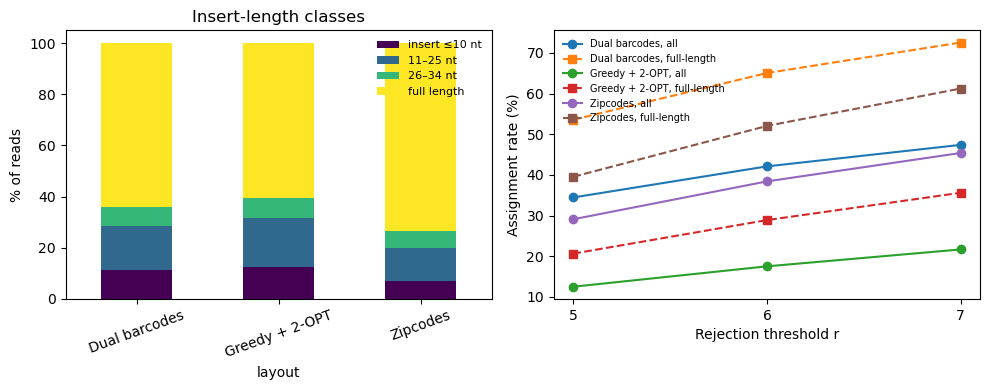

decoy_fraction_all                     decoy_fraction_short  \
threshold                       5         6         7                    5   
layout                                                                       
Dual barcodes            0.013398  0.031550  0.048463             0.223849   
Greedy + 2-OPT           0.000000  0.000280  0.004279             0.000000   
Zipcodes                 0.014798  0.031702  0.055835             0.628975   

                                    
threshold              6         7  
layout                              
Dual barcodes   0.274974  0.294014  
Greedy + 2-OPT  0.065217  0.239506  
Zipcodes        0.602132  0.663859

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
show = acc[acc.threshold == 7].set_index("layout")
fracs = show[["short_le10", "short_11_25", "short_26_34", "full_length"]].div(show.reads, axis=0) * 100
fracs.columns = ["insert ≤10 nt", "11–25 nt", "26–34 nt", "full length"]
fracs.plot(kind="bar", stacked=True, ax=axes[0], colormap="viridis", rot=20)
axes[0].set_ylabel("% of reads")
axes[0].set_title("Insert-length classes")
axes[0].legend(frameon=False, fontsize=8)
for name, d in acc.groupby("layout"):
    axes[1].plot(d.threshold, d.assignment_rate_all * 100, "o-", label=f"{name}, all")
    axes[1].plot(d.threshold, d.assignment_rate_full * 100, "s--", label=f"{name}, full-length")
axes[1].set_xlabel("Rejection threshold r")
axes[1].set_ylabel("Assignment rate (%)")
axes[1].set_xticks([5, 6, 7])
axes[1].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "read_accounting.pdf")
plt.show()

decoy = acc.pivot_table(index="layout", columns="threshold", values=["decoy_fraction_all", "decoy_fraction_short"])
decoy